# LUMA - Lokalny Urok Mistrzostwa Artystycznego
LUMA to lokalny jarmark, który rośnie z tygodnia na tydzień: coraz więcej wystawców, więcej gości (miejscowych i turystów), okazjonalne promocje i sezonowość.

# Import bibliotek

In [120]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd



In [121]:
# Wygenerowanie syntetycznych danych

SEED = 20261020
rng = np.random.default_rng(SEED)

# Przygotowanie stałych

LUMA_FULL = "Lokalny Urok Mistrzostwa Artystycznego"
CATEGORIES = ["Ceramika", "Tekstylia", "Biżuteria", "Rękodzieło", "Przetwory", "Dekoracje", "Stolarka", "Masarstwo", "Alkohole"]

# Przygotowanie bazowych danych syntetycznych

# "Katalog"

catalog = pd.DataFrame({
    "category": CATEGORIES,
    "demand_loc_base": [120, 180, 130, 80, 160, 150, 70, 90, 110], # Średni lokalny popyt (szt./tydz.) na produkty w każdej kategorii
    "demand_tur_base": [60, 40, 80, 30, 90, 30, 50, 40, 80], # Średni turystyczny popyt (szt./tydz.) na produkty w każdej kategorii
    "price_pln_base": [8, 120, 150, 230, 40, 35, 250, 215, 135], # Średnia cena jednostkowa (PLN/szt.) produktów w każdej kategorii
})

# Wylicz typowy (średni) przychód tygodniowy: (lokalni i turyści) * cena jednostkowa
catalog["revenue_avg_pln"] = (catalog["demand_loc_base"] + catalog["demand_tur_base"]) * catalog["price_pln_base"]

display(catalog)

def determine_demand(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    df = catalog[["category", "demand_loc_base", "demand_tur_base"]].copy()
    eps_loc = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    eps_tur = np.clip(rng.normal(loc=1.0, scale=variance, size=len(df)), 0.5, 1.8)
    df["demand_loc"] = (df["demand_loc_base"] * (1 + boost_loc)) * eps_loc
    df["demand_tur"] = (df["demand_tur_base"] * (1 + boost_tur)) * eps_tur
    df["demand_loc"] = np.maximum(df["demand_loc"].round().astype(int), 0)
    df["demand_tur"] = np.maximum(df["demand_tur"].round().astype(int), 0)
    return df[["category", "demand_loc", "demand_tur"]]

,category,demand_loc_base,demand_tur_base,price_pln_base,revenue_avg_pln
0,Ceramika,120,60,8,1440
1,Tekstylia,180,40,120,26400
2,Biżuteria,130,80,150,31500
3,Rękodzieło,80,30,230,25300
4,Przetwory,160,90,40,10000
5,Dekoracje,150,30,35,6300
6,Stolarka,70,50,250,30000
7,Masarstwo,90,40,215,27950
8,Alkohole,110,80,135,25650


In [122]:
def count_revenue(catalog, demand_df):
    df = demand_df.merge(
        catalog[["category", "price_pln_base"]], on="category", how="left"
    )
    df["revenue_loc"] = df["demand_loc"] * df["price_pln_base"]
    df["revenue_tur"] = df["demand_tur"] * df["price_pln_base"]
    df["revenue_pln"] = df["revenue_loc"] + df["revenue_tur"]
    return df[["category", "revenue_loc", "revenue_tur", "revenue_pln"]]


In [123]:
# Generowanie danych tygodniowych

def generate_weekly_data(catalog, rng, variance=0.15, boost_loc=0.0, boost_tur=0.0):
    demand_df = determine_demand(catalog, rng, variance, boost_loc, boost_tur)
    revenue_df = count_revenue(catalog, demand_df)
    return revenue_df

In [124]:
# Wygenerowanie danych tygodniowych
t1 = generate_weekly_data(catalog, rng)
t1.merge(catalog[["category", "price_pln_base"]], on="category", how="left")
print("Tydzień 1 - przychody per ketegoria (PLN)")
display(t1)
print("Łączny przychód w tygodniu 1 (PLN): ", t1["revenue_pln"].sum())

Tydzień 1 - przychody per ketegoria (PLN)


,category,revenue_loc,revenue_tur,revenue_pln
0,Ceramika,688,392,1080
1,Tekstylia,21240,3360,24600
2,Biżuteria,13350,11700,25050
3,Rękodzieło,22540,6440,28980
4,Przetwory,7720,3680,11400
5,Dekoracje,4900,1120,6020
6,Stolarka,19000,14250,33250
7,Masarstwo,18275,8815,27090
8,Alkohole,18630,10260,28890


Łączny przychód w tygodniu 1 (PLN):  186360


<Axes: >

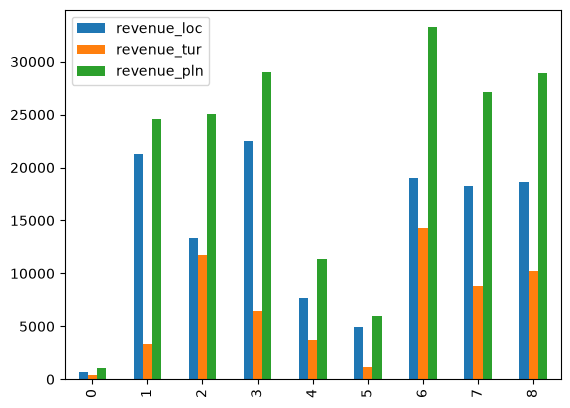

In [125]:
t1.plot.bar() 

<Axes: >

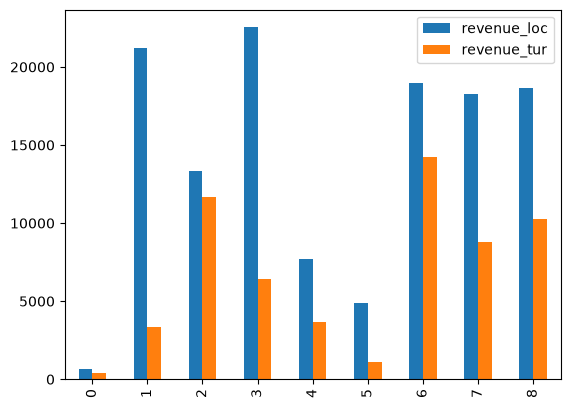

In [126]:
t1[["revenue_loc", "revenue_tur"]].plot.bar()

<Axes: >

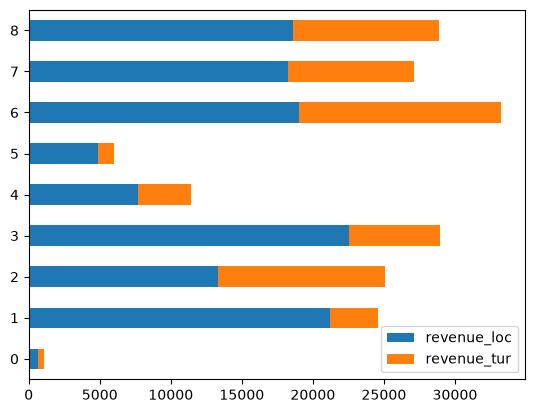

In [127]:
t1[["revenue_loc", "revenue_tur"]].plot.barh(stacked=True)

<BarContainer object of 9 artists>

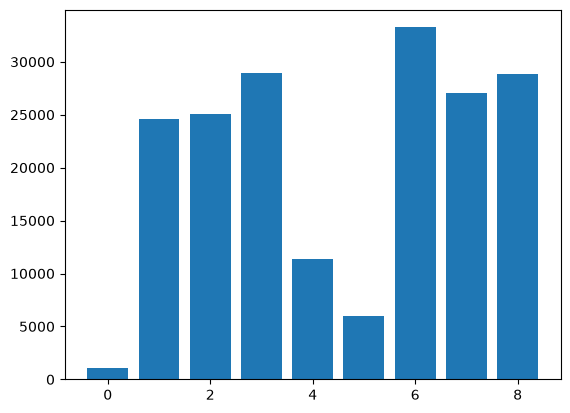

In [128]:
heights = t1["revenue_pln"]
plt.bar(range(len(heights)), heights)

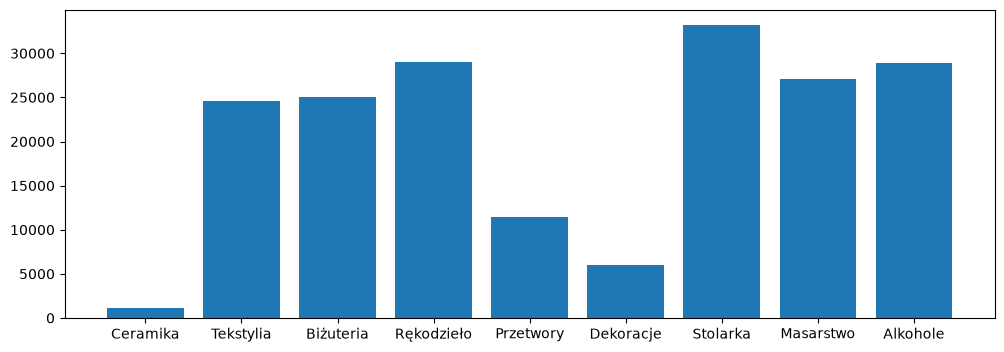

In [129]:
# Jawne tworzenie i wyswietlanie wykresu

heights = t1["revenue_pln"]
categories = t1["category"]

plt.figure(figsize=(12, 4)) # tylko canva wykresu
plt.bar(categories, heights)
plt.show()

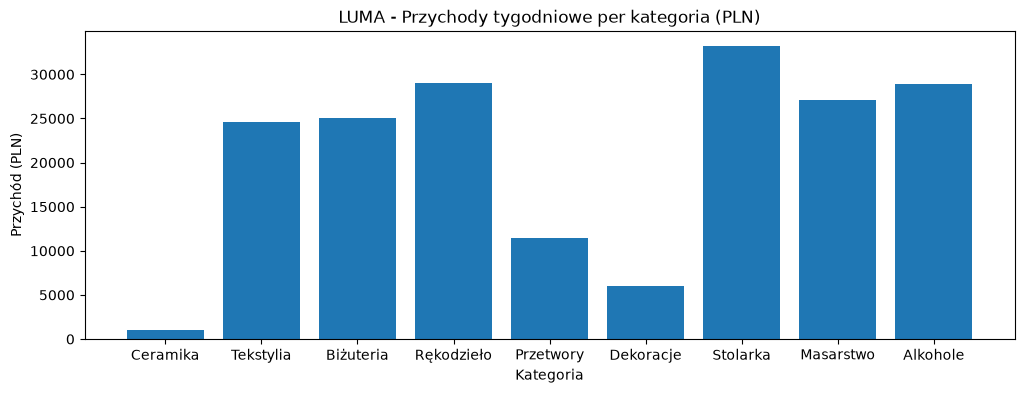

In [130]:
plt.figure(figsize=(12, 4)) # tylko canva wykresu
plt.bar(categories, heights)
plt.title("LUMA - Przychody tygodniowe per kategoria (PLN)")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.show()

In [131]:
def format_pln(x: float) -> str:
    return f"{round(x):,} zł".replace(",", "\u202f")

print(format_pln(1234567.892))  # Output: 1,234,568 PLN

1 234 568 zł


In [132]:
def label_bars_pln(bars):
    for bar in bars:
        x = bar.get_x() + bar.get_width() / 2
        y = bar.get_height()
        plt.text(x, y, format_pln(y), ha='center', va='bottom')

In [133]:
def pad_axis(factor=0.07):
    ymin, ymax = plt.ylim()
    pad = (ymax - ymin) * factor
    plt.ylim(ymin, ymax + pad)
    

In [134]:
def format_ytics_tys():
    ypos, _ = plt.yticks()
    ylab_new = [format_pln(y) for y in ypos]
    plt.yticks(ypos, ylab_new)

In [135]:
t1_sorted = t1.sort_values(by="revenue_pln", ascending=False).reset_index()
categories = t1_sorted["category"]
heights = t1_sorted["revenue_pln"]

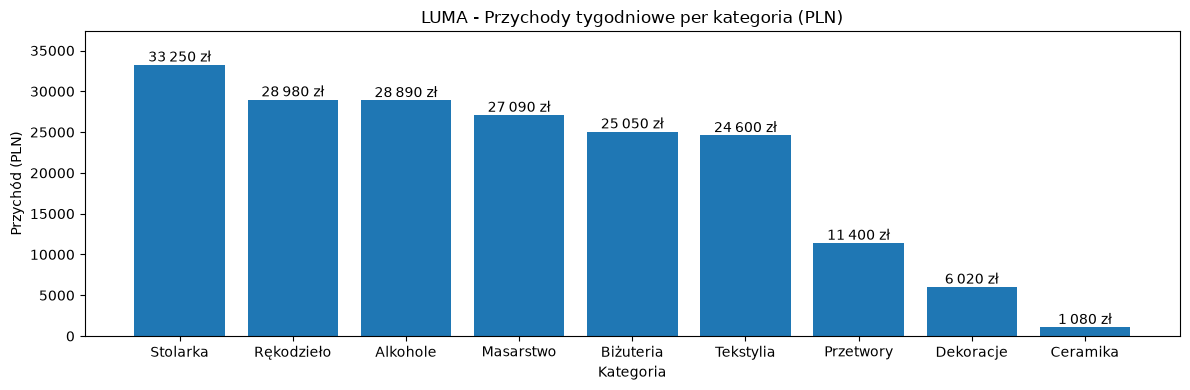

In [136]:

plt.figure(figsize=(12, 4)) # tylko canva wykresu
bars = plt.bar(categories, heights)
pad_axis(factor=0.07)
label_bars_pln(bars)
plt.title("LUMA - Przychody tygodniowe per kategoria (PLN)")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

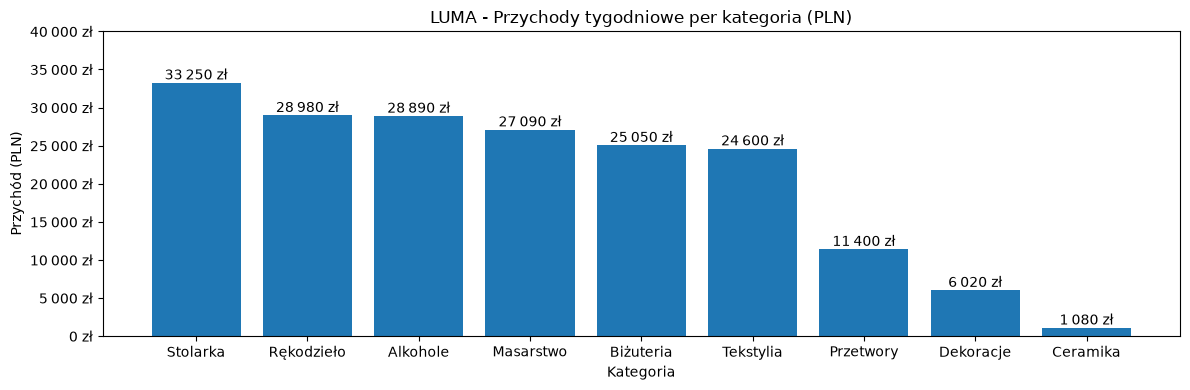

In [137]:
plt.figure(figsize=(12, 4))
bars = plt.bar(categories, heights)
pad_axis()
label_bars_pln(bars)
plt.title("LUMA - Przychody tygodniowe per kategoria (PLN)")
format_ytics_tys()
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()

In [138]:
def format_tys(x: float, decimals=0) -> str:
    value = x / 1000.0
    if decimals == 0:
        s = f"{int(round(value)):,}".replace(",", "\u202f")
    else:
        s = f"{value:,.{decimals}f} tys. zł".replace(",", "\u202f").replace(".", ",")
    return s + " tys. zł"


def format_mln(x: float, decimals=0) -> str:
    value = x / 1_000_000.0
    if decimals == 0:
        return f"{int(round(value)):,} mln zł".replace(",", "\u202f")
    else:
        return f"{value:,.{decimals}f} mln zł".replace(",", "\u202f").replace(".", ",")


print(format_tys(123456789.456, 2))

123 456,79 tys, zł tys. zł


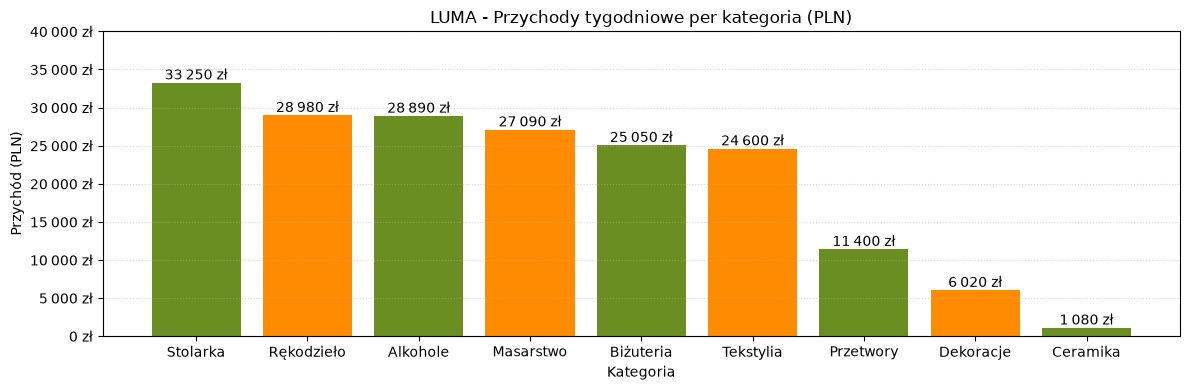

In [140]:
# Siatka w tle wykresu
plt.figure(figsize=(12, 4))

# Pass a list of two colors. It will repeat automatically (e.g., color1, color2, color1, color2...)
colors = ["olivedrab", "darkorange"]
bars = plt.bar(categories, heights, color=colors)

pad_axis()
label_bars_pln(bars)
format_ytics_tys()
plt.grid(axis='y', linestyle=':', alpha=0.5)
plt.title("LUMA - Przychody tygodniowe per kategoria (PLN)")
plt.xlabel("Kategoria")
plt.ylabel("Przychód (PLN)")
plt.tight_layout()
plt.show()
